In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow_datasets as tfds
import cv2
from transformers import CLIPTokenizer
from dataclasses import dataclass
from torch.utils.data import Dataset
import os
import torchvision.transforms as T
import torch.nn.functional as F
from PIL import Image
import torch
import pandas as pd
import requests
from io import BytesIO
from pathlib import Path
from tqdm import tqdm

c:\files\PracticalML\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Clear GPU memory cache
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Using device: cuda


In [ ]:
# Load NASA APOD dataset and filter only images with explanations
csv_path = "/kaggle/input/nasa-astronomy-picture-of-the-day-apod-extended/nasa-apod-dataset.csv"
df_temp = pd.read_csv(csv_path, sep=';')
df_filtered = df_temp[(df_temp['media_type'] == 'image') & (df_temp['explanation'].notna())]

# Use half of the dataset for training
half_size = len(df_filtered) // 2

In [ ]:
# Load CLIP tokenizer for text encoding
tokenizer = CLIPTokenizer.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    subfolder="tokenizer"
)

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

In [ ]:
# Training configuration dataclass
@dataclass
class TrainingConfig:
    image_size = 512  # Input image resolution
    train_batch_size = 16  # Batch size for training
    eval_batch_size = 8  # Batch size for evaluation
    num_epochs = 10  # Number of training epochs
    gradient_accumulation_steps = 4  # Steps to accumulate gradients
    learning_rate = 1e-5  # Learning rate for optimizer
    lr_warmup_steps = 300  # Warmup steps for scheduler
    save_image_epochs = 1  # Save sample images every N epochs
    save_model_epochs = 1   # Save model checkpoint every N epochs
    mixed_precision = "fp16"  # Use mixed precision training
    output_dir = "ddpm-NASA-256"  # Output directory for checkpoints
    push_to_hub = False
    hub_private_repo = False
    overwrite_output_dir = True
    seed = 0

config = TrainingConfig()

In [ ]:
# Custom Dataset for NASA APOD images with text descriptions
class IDataset(Dataset):
    def __init__(self, csv_path, tokenizer, image_size=512, vae=None, cache_dir="cached_images", use_title_only=False, limit=None, use_cached_latents=False, latents_cache_dir="cached_latents"):
        self.tokenizer = tokenizer
        self.vae = vae
        self.use_title_only = use_title_only
        self.use_cached_latents = use_cached_latents
        self.latents_cache_dir = Path(latents_cache_dir) if use_cached_latents else None
        
        # Load and filter dataset
        df = pd.read_csv(csv_path, sep=';')
        df = df[df['media_type'] == 'image']
        df = df.dropna(subset=['media_url', 'explanation'])
        
        # Sort by date
        if 'date' in df.columns:
            df['date'] = pd.to_datetime(df['date'])
            df = df.sort_values('date', ascending=False)
        
        if limit is not None:
            df = df.head(limit)
        
        self.data = df.reset_index(drop=True)
        
        # Setup image cache directory
        self.cache_dir = Path(cache_dir)
        self.cache_dir.mkdir(exist_ok=True)
        
        # Image transforms
        self.transform = T.Compose([
            T.Resize((image_size, image_size)),
            T.ToTensor(),
        ])
        
        # VAE encoding transform
        if self.vae is not None:
            self.vae_encode_transform = T.Compose([
                T.Resize((512, 512)),
                T.ToTensor(),
            ])

    def _download_image(self, url, idx):
        cache_path = self.cache_dir / f"{idx}.jpg"
        
        # Return cached image if exists
        if cache_path.exists():
            return Image.open(cache_path).convert("RGB")
        
        # Download and cache image
        try:
            response = requests.get(url, timeout=10)
            response.raise_for_status()
            image = Image.open(BytesIO(response.content)).convert("RGB")
            image.save(cache_path, "JPEG")
            return image
        except Exception as e:
            print(f"Error downloading {url}: {e}")
            return None

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        
        url = row['media_url']
        image = self._download_image(url, idx)
        
        # Create black image if download failed
        if image is None:
            image = Image.new('RGB', (512, 512), color='black')
        
        # Load pre-cached latents if available
        if self.use_cached_latents and self.latents_cache_dir is not None:
            latent_path = self.latents_cache_dir / f"{idx}.pt"
            if latent_path.exists():
                image = torch.load(latent_path)
            else:
                image = torch.zeros((4, 64, 64))
        
        # Encode image to latents on-the-fly using VAE
        elif self.vae is not None:
            image_for_vae = self.vae_encode_transform(image)
            with torch.no_grad():
                image_for_vae = image_for_vae * 2.0 - 1.0  # Normalize to [-1, 1]
                image_for_vae = image_for_vae.unsqueeze(0)
                vae_device = next(self.vae.parameters()).device
                image_for_vae = image_for_vae.to(vae_device)
                latents = self.vae.encode(image_for_vae).latent_dist.sample()
                latents = latents * self.vae.config.scaling_factor
                image = latents.squeeze(0).cpu()
                del image_for_vae
        else:
            image = self.transform(image)
        
        # Prepare text: title only or title + explanation
        if self.use_title_only:
            text = row['title']
        else:
            text = f"{row['title']}. {row['explanation']}"
        
        # Tokenize text for CLIP
        encoding = self.tokenizer(
            text,
            padding="max_length",
            truncation=True,
            max_length=77,
            return_tensors="pt"
        )

        return {
            "pixel_values": image,
            "input_ids": encoding.input_ids.squeeze(0)
        }

In [ ]:
from diffusers import UNet2DConditionModel
from peft import LoraConfig, get_peft_model

# Load pre-trained UNet from Stable Diffusion
model = UNet2DConditionModel.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    subfolder="unet"
).to(device)

# Enable memory-efficient training
model.enable_gradient_checkpointing()

# Freeze all base model parameters
for param in model.parameters():
    param.requires_grad = False

# LoRA config: only train attention layers with low-rank matrices
lora_config = LoraConfig(
    r=16,  # Rank of LoRA matrices
    lora_alpha=32,  # Scaling factor
    init_lora_weights="gaussian",
    target_modules=["to_k", "to_q", "to_v", "to_out.0"],  # Target attention layers
)

# Apply LoRA to UNet
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

# Print model configuration
base_model = model.base_model.model if hasattr(model, 'base_model') else model

print(f"Model sample_size: {base_model.config.sample_size}")
print(f"Model in_channels: {base_model.config.in_channels}")
print(f"Model out_channels: {base_model.config.out_channels}")

2025-11-23 11:04:14.719340: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1763895854.905414      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1763895854.959033      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

trainable params: 3,188,736 || all params: 862,709,700 || trainable%: 0.3696
Model sample_size: 64
Model in_channels: 4
Model out_channels: 4


In [ ]:
# Load VAE
from diffusers import AutoencoderKL

vae = AutoencoderKL.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    subfolder="vae"
)

# VAE is frozen during training
vae.eval()
vae.requires_grad_(False)

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

AutoencoderKL(
  (encoder): Encoder(
    (conv_in): Conv2d(3, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (down_blocks): ModuleList(
      (0): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0-1): 2 x ResnetBlock2D(
            (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
            (conv1): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (norm2): GroupNorm(32, 128, eps=1e-06, affine=True)
            (dropout): Dropout(p=0.0, inplace=False)
            (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
            (nonlinearity): SiLU()
          )
        )
        (downsamplers): ModuleList(
          (0): Downsample2D(
            (conv): Conv2d(128, 128, kernel_size=(3, 3), stride=(2, 2))
          )
        )
      )
      (1): DownEncoderBlock2D(
        (resnets): ModuleList(
          (0): ResnetBlock2D(
            (norm1): GroupNorm(32, 128, eps=1e-06, affine=True)
            (c

In [ ]:
# Pre-compute and cache latents for faster training
from concurrent.futures import ThreadPoolExecutor, as_completed

# Setup cache directories
latents_cache_dir = Path("cached_latents")
latents_cache_dir.mkdir(exist_ok=True)

df = df_filtered.head(half_size).reset_index(drop=True)

# Transform for VAE encoding (always 512x512)
vae_encode_transform = T.Compose([
    T.Resize((512, 512)),
    T.ToTensor(),
])

vae.to(device)
vae.eval()

image_cache_dir = Path("cached_images")
image_cache_dir.mkdir(exist_ok=True)

def load_image(idx, row, image_cache_dir):
    try:
        image_cache_path = image_cache_dir / f"{idx}.jpg"
        if image_cache_path.exists():
            return idx, Image.open(image_cache_path).convert("RGB")
        
        url = row['media_url']
        response = requests.get(url, timeout=10)
        response.raise_for_status()
        image = Image.open(BytesIO(response.content)).convert("RGB")
        image.save(image_cache_path, "JPEG")
        return idx, image
    except:
        return idx, None

# Process images in batches
batch_size = 16
for batch_start in tqdm(range(0, len(df), batch_size)):
    batch_end = min(batch_start + batch_size, len(df))
    
    # Skip already cached latents
    indices_to_process = []
    for idx in range(batch_start, batch_end):
        if not (latents_cache_dir / f"{idx}.pt").exists():
            indices_to_process.append(idx)
    
    if not indices_to_process:
        continue
    
    # Load images in parallel using thread pool
    with ThreadPoolExecutor(max_workers=8) as executor:
        futures = {executor.submit(load_image, idx, df.iloc[idx], image_cache_dir): idx for idx in indices_to_process}
        images_dict = {}
        for future in as_completed(futures):
            idx, image = future.result()
            if image is not None:
                images_dict[idx] = image
    
    # Prepare batch for VAE encoding
    batch_images = []
    batch_paths = []
    for idx in indices_to_process:
        if idx in images_dict:
            image_for_vae = vae_encode_transform(images_dict[idx])
            batch_images.append(image_for_vae)
            batch_paths.append((idx, latents_cache_dir / f"{idx}.pt"))
    
    if not batch_images:
        continue
    
    # Encode images to latent space
    with torch.no_grad():
        batch_tensor = torch.stack(batch_images) * 2.0 - 1.0  # Normalize to [-1, 1]
        batch_tensor = batch_tensor.to(device)
        latents = vae.encode(batch_tensor).latent_dist.sample()
        latents = latents * vae.config.scaling_factor
        latents = latents.cpu()
    
    # Save latents to cache
    for i, (idx, latent_path) in enumerate(batch_paths):
        torch.save(latents[i], latent_path)

print(f"Precoded {len([f for f in latents_cache_dir.glob('*.pt')])} latents")

 79%|███████▊  | 247/314 [24:33<08:12,  7.35s/it]/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (136037232 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
100%|██████████| 314/314 [32:55<00:00,  6.29s/it]

Precoded 5009 latents


In [ ]:
# Initialize dataset with pre-cached latents
dataset = IDataset(
    csv_path=csv_path,
    tokenizer=tokenizer,
    image_size=config.image_size,
    vae=None,  # VAE not needed - using cached latents
    limit=half_size,
    use_cached_latents=True, # Load pre-computed latents
    latents_cache_dir="cached_latents"
)

print(f"Dataset size: {len(dataset)}")
torch.cuda.empty_cache() if torch.cuda.is_available() else None

Dataset size: 5021


In [ ]:
# Create DataLoader for training
train_dataloader = torch.utils.data.DataLoader(
    dataset,
    batch_size=config.train_batch_size,
    shuffle=True,  # Shuffle for training
    num_workers=0,  # Single worker for latent loading
    pin_memory=False,
)

In [ ]:
# Load CLIP text encoder
from transformers import CLIPTextModel

text_encoder = CLIPTextModel.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    subfolder="text_encoder"
)

# Text encoder is frozen during training
text_encoder.eval()
text_encoder.requires_grad_(False)

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

text_encoder/model.safetensors:   0%|          | 0.00/492M [00:00<?, ?B/s]

CLIPTextModel(
  (text_model): CLIPTextTransformer(
    (embeddings): CLIPTextEmbeddings(
      (token_embedding): Embedding(49408, 768)
      (position_embedding): Embedding(77, 768)
    )
    (encoder): CLIPEncoder(
      (layers): ModuleList(
        (0-11): 12 x CLIPEncoderLayer(
          (self_attn): CLIPAttention(
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (layer_norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (mlp): CLIPMLP(
            (activation_fn): QuickGELUActivation()
            (fc1): Linear(in_features=768, out_features=3072, bias=True)
            (fc2): Linear(in_features=3072, out_features=768, bias=True)
          )
          (layer_norm2): LayerNorm((768,), eps=1e

In [ ]:
text_hidden = text_encoder.config.hidden_size
print("text_encoder.config.hidden_size:", text_encoder.config.hidden_size)

text_encoder.config.hidden_size: 768


In [ ]:
# Test forward pass through model
sample_image = dataset[0]["pixel_values"].unsqueeze(0)
print("Input shape:", sample_image.shape)

sample = dataset[0]
sample_image = sample["pixel_values"].unsqueeze(0).to(device)
input_ids = sample["input_ids"].unsqueeze(0).to(device)

text_encoder.to(device)

# Get text embeddings
with torch.no_grad():
    encoder_hidden_states = text_encoder(input_ids).last_hidden_state

# Test UNet forward pass
output = model(sample_image, timestep=0, encoder_hidden_states=encoder_hidden_states)
print("Output shape:", output.sample.shape)

# Cleanup
del sample_image, input_ids, encoder_hidden_states, output
torch.cuda.empty_cache() if torch.cuda.is_available() else None

Input shape: torch.Size([1, 4, 64, 64])
Output shape: torch.Size([1, 4, 64, 64])


In [ ]:
# Load noise scheduler
from diffusers import DDPMScheduler

noise_scheduler = DDPMScheduler.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    subfolder="scheduler"
)

print(f"Scheduler num_train_timesteps: {noise_scheduler.config.num_train_timesteps}")
print(f"Scheduler beta_schedule: {noise_scheduler.config.beta_schedule}")

# Test noise addition
sample = dataset[0]
sample_image = sample["pixel_values"].unsqueeze(0).to(device)

batch_size = sample_image.shape[0]
device = sample_image.device

# Add noise at timestep 50
noise = torch.randn_like(sample_image).to(device)
timesteps = torch.tensor([50] * batch_size, dtype=torch.long).to(device)

noisy_image = noise_scheduler.add_noise(sample_image, noise, timesteps)

# Cleanup
del sample_image, noise, timesteps, noisy_image
torch.cuda.empty_cache() if torch.cuda.is_available() else None

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

Scheduler num_train_timesteps: 1000
Scheduler beta_schedule: scaled_linear


In [ ]:
# Test training step: noise prediction and loss calculation
sample = dataset[0]
sample_image = sample["pixel_values"].unsqueeze(0).to(device)
input_ids = sample["input_ids"].unsqueeze(0).to(device)

# Get text embeddings
with torch.no_grad():
    encoder_hidden_states = text_encoder(input_ids).last_hidden_state

# Add noise to image
batch_size = sample_image.shape[0]
noise = torch.randn_like(sample_image).to(device)
timesteps = torch.tensor([50] * batch_size, dtype=torch.long).to(device)
noisy_image = noise_scheduler.add_noise(sample_image, noise, timesteps)

# Predict noise
noise_pred = model(
    noisy_image,
    timestep=timesteps,
    encoder_hidden_states=encoder_hidden_states
).sample

# Calculate MSE loss between predicted and actual noise
loss = F.mse_loss(noise_pred, noise)

# Cleanup
del sample_image, input_ids, encoder_hidden_states, noise, timesteps, noisy_image, noise_pred
torch.cuda.empty_cache() if torch.cuda.is_available() else None

In [ ]:
# Setup optimizer and learning rate scheduler
from diffusers.optimization import get_cosine_schedule_with_warmup

# Only optimize LoRA parameters
trainable_params = list(filter(lambda p: p.requires_grad, model.parameters()))
optimizer = torch.optim.AdamW(trainable_params, lr=config.learning_rate)

# Cosine schedule with warmup for stable training
lr_scheduler = get_cosine_schedule_with_warmup(
    optimizer=optimizer,
    num_warmup_steps=config.lr_warmup_steps,
    num_training_steps=(len(train_dataloader) * config.num_epochs),
)

In [ ]:
# Evaluation function for generating sample images during training
from diffusers.utils import make_image_grid

def evaluate(config, epoch, model, text_encoder, noise_scheduler, tokenizer, vae):
    # Test prompts for evaluation
    test_prompts = [
        "Milky Way",
        "Black hole",
        "Space station driving in space",
        "Nebula in space",
    ]
    
    # Repeat prompts to fill batch
    if len(test_prompts) < config.eval_batch_size:
        test_prompts = test_prompts * ((config.eval_batch_size // len(test_prompts)) + 1)

    test_prompts = test_prompts[:config.eval_batch_size]

    # Set models to eval mode
    model.eval()
    text_encoder.eval()
    vae.eval()
    
    with torch.no_grad():
        # Tokenize prompts
        text_input = tokenizer(
            test_prompts,
            padding="max_length",
            max_length=77,
            truncation=True,
            return_tensors="pt"
        )
        model_device = next(model.parameters()).device
        input_ids = text_input.input_ids.to(model_device)

        # Get text embeddings
        encoder_hidden_states = text_encoder(input_ids).last_hidden_state
        
        # Start from random noise
        latent_height = latent_width = 64
        latent_shape = (config.eval_batch_size, 4, latent_height, latent_width)
        latents = torch.randn(latent_shape, device=model_device)

        # Denoising loop
        noise_scheduler.set_timesteps(50)
        for t in noise_scheduler.timesteps:
            noise_pred = model(
                latents,
                timestep=t,
                encoder_hidden_states=encoder_hidden_states,
                return_dict=False
            )[0]
            
            latents = noise_scheduler.step(noise_pred, t, latents).prev_sample
        
        # Decode latents to images
        latents = latents / vae.config.scaling_factor
        images = vae.decode(latents).sample
        images = (images / 2 + 0.5).clamp(0, 1)
        images = images.cpu().permute(0, 2, 3, 1).numpy()
        images = (images * 255).round().astype("uint8")
        pil_images = [Image.fromarray(image) for image in images]
        
        # Resize if needed
        if config.image_size < 512:
            pil_images = [img.resize((config.image_size, config.image_size), Image.LANCZOS) for img in pil_images]

    # Save results as grid
    image_grid = make_image_grid(pil_images, rows=4, cols=2)
    test_dir = os.path.join(config.output_dir, "samples")
    os.makedirs(test_dir, exist_ok=True)
    image_grid.save(f"{test_dir}/{epoch:04d}.png")
    
    # Save prompts
    with open(f"{test_dir}/{epoch:04d}_prompts.txt", "w") as f:
        for i, prompt in enumerate(test_prompts):
            f.write(f"Image {i}: {prompt}\n")
    
    print(f"Generated {len(pil_images)} images for epoch {epoch}")

In [ ]:
# Main training loop with accelerate for distributed training
from accelerate import Accelerator
from huggingface_hub import create_repo, upload_folder
from tqdm.auto import tqdm
from pathlib import Path
import os
import torch
import torch.nn.functional as F

def train_loop(config, model, text_encoder, noise_scheduler, optimizer, train_dataloader, lr_scheduler):
    # Setup accelerator for mixed precision and multi-GPU training
    accelerator = Accelerator(
        mixed_precision=config.mixed_precision,
        gradient_accumulation_steps=config.gradient_accumulation_steps,
        log_with="tensorboard",
        project_dir=os.path.join(config.output_dir, "logs"),
    )

    # Create output directory and init trackers on main process
    if accelerator.is_main_process:
        if config.output_dir is not None:
            os.makedirs(config.output_dir, exist_ok=True)
        if config.push_to_hub:
            repo_id = create_repo(
                repo_id=config.hub_model_id or Path(config.output_dir).name, exist_ok=True
            ).repo_id
        accelerator.init_trackers("train_example")

    # Prepare models, optimizer, dataloader for distributed training
    model, text_encoder, optimizer, train_dataloader, lr_scheduler = accelerator.prepare(
        model, text_encoder, optimizer, train_dataloader, lr_scheduler
    )

    global_step = 0

    for epoch in range(config.num_epochs):
        progress_bar = tqdm(
            total=len(train_dataloader), 
            disable=not accelerator.is_local_main_process,
            desc=f"Epoch {epoch}",
            leave=True,
            ncols=100,
            mininterval=0.1,
            maxinterval=1.0
        )

        for step, batch in enumerate(train_dataloader):
            # Get clean latent images
            clean_images = batch["pixel_values"]

            # Sample random noise
            noise = torch.randn(clean_images.shape, device=clean_images.device)
            bs = clean_images.shape[0]

            # Sample random timesteps
            timesteps = torch.randint(
                0, noise_scheduler.config.num_train_timesteps, (bs,), device=clean_images.device,
                dtype=torch.int64
            )

            # Add noise to latents
            noisy_images = noise_scheduler.add_noise(clean_images, noise, timesteps)

            # Training step with gradient accumulation
            with accelerator.accumulate(model):
                # Get text embeddings and predict noise
                encoder_hidden_states = text_encoder(batch["input_ids"]).last_hidden_state
                noise_pred = model(noisy_images, timestep=timesteps, encoder_hidden_states=encoder_hidden_states, return_dict=False)[0]

                # Calculate MSE loss
                loss = F.mse_loss(noise_pred, noise)
                accelerator.backward(loss)

                # Gradient clipping
                if accelerator.sync_gradients:
                    trainable_params = [p for p in model.parameters() if p.requires_grad]
                    accelerator.clip_grad_norm_(trainable_params, 1.0)
                optimizer.step()
                lr_scheduler.step()
                optimizer.zero_grad()
                
                del encoder_hidden_states, noise_pred

            # Update progress bar
            if accelerator.is_local_main_process:
                logs = {"loss": loss.detach().item(), "lr": lr_scheduler.get_last_lr()[0], "step": global_step}
                progress_bar.set_postfix(**logs)
                progress_bar.update(1)
            
            accelerator.log({"loss": loss.detach().item(), "lr": lr_scheduler.get_last_lr()[0]}, step=global_step)
            global_step += 1
            
            # Periodic memory cleanup
            if global_step % 10 == 0 and torch.cuda.is_available():
                torch.cuda.empty_cache()

        if accelerator.is_local_main_process:
            progress_bar.close()
        
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        # Save samples and checkpoints at end of epoch
        if accelerator.is_main_process:
            # Generate sample images
            if (epoch + 1) % config.save_image_epochs == 0 or epoch == config.num_epochs - 1:

                # Unwrap models for evaluation
                eval_model = accelerator.unwrap_model(model)
                eval_text_encoder = accelerator.unwrap_model(text_encoder)
                eval_vae = vae.module if hasattr(vae, 'module') else vae
                
                if hasattr(eval_model, 'module'):
                    eval_model = eval_model.module
                if hasattr(eval_text_encoder, 'module'):
                    eval_text_encoder = eval_text_encoder.module
                if hasattr(eval_vae, 'module'):
                    eval_vae = eval_vae.module
                
                evaluate(
                    config, 
                    epoch, 
                    eval_model, 
                    eval_text_encoder,
                    noise_scheduler,
                    tokenizer,
                    eval_vae
                )

            # Save model checkpoint
            if (epoch + 1) % config.save_model_epochs == 0 or epoch == config.num_epochs - 1:
                epoch_dir = os.path.join(config.output_dir, f"checkpoint-{epoch+1}")
                os.makedirs(epoch_dir, exist_ok=True)
                
                unwrapped_model = accelerator.unwrap_model(model)
                if hasattr(unwrapped_model, 'module'):
                    unwrapped_model = unwrapped_model.module
                
                # Save only LoRA weights
                unwrapped_model.save_pretrained(os.path.join(epoch_dir, "unet"))
                
                print(f"LoRA weights saved at epoch {epoch+1} to {epoch_dir}/unet")

In [ ]:
# Check GPU memory usage
!nvidia-smi

Sun Nov 23 11:37:40 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 560.35.03              Driver Version: 560.35.03      CUDA Version: 12.6     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   76C    P0             47W /   70W |    4771MiB /  15360MiB |      5%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
if torch.cuda.is_available():
    num_gpus = torch.cuda.device_count()
    print(f"{num_gpus} GPU(s)")
    if num_gpus > 1:
        model = torch.nn.DataParallel(model)
        text_encoder = torch.nn.DataParallel(text_encoder)
        vae = torch.nn.DataParallel(vae)

# Start training loop
train_loop(config, model, text_encoder, noise_scheduler, optimizer, train_dataloader, lr_scheduler)

2 GPU(s)


Epoch 0:   0%|                                                              | 0/314 [00:00<?, ?it/s]

/usr/local/lib/python3.11/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (136037232 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


Generated 8 images for epoch 0
LoRA weights saved at epoch 1 to ddpm-NASA-256/checkpoint-1/unet


Epoch 1:   0%|                                                              | 0/314 [00:00<?, ?it/s]

...

Generated 8 images for epoch 7
LoRA weights saved at epoch 8 to ddpm-NASA-256/checkpoint-8/unet


Epoch 8:   0%|                                                              | 0/314 [00:00<?, ?it/s]

Generated 8 images for epoch 8
LoRA weights saved at epoch 9 to ddpm-NASA-256/checkpoint-9/unet


Epoch 9:   0%|                                                              | 0/314 [00:00<?, ?it/s]

Generated 8 images for epoch 9
LoRA weights saved at epoch 10 to ddpm-NASA-256/checkpoint-10/unet


Last image (Epoch 10):

Prompts:
Image 0: Milky Way
Image 1: Black hole
Image 2: Space station driving in space
Image 3: Nebula in space
Image 4: Milky Way
Image 5: Black hole
Image 6: Space station driving in space
Image 7: Nebula in space



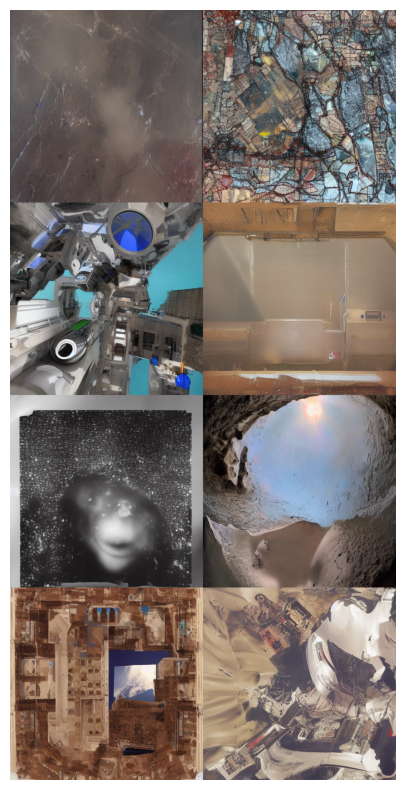

In [ ]:
# Display the last generated sample grid
import glob

sample_images = sorted(glob.glob(f"{config.output_dir}/samples/*.png"))

if sample_images:
    # Load last generated image grid
    last_image_path = sample_images[-1]
    last_image = Image.open(last_image_path)
    
    # Load and display prompts
    prompts_file = last_image_path.replace('.png', '_prompts.txt')
    if os.path.exists(prompts_file):
        with open(prompts_file, 'r') as f:
            prompts = f.read()
        
        epoch_num = int(os.path.basename(last_image_path).split('.')[0])
        print(f"Last image (Epoch {epoch_num+1}):")
        print(f"\nPrompts:\n{prompts}")
    
    # Show image grid
    plt.figure(figsize=(10, 10))
    plt.imshow(last_image)
    plt.axis('off')
    plt.show()

In [ ]:
# Run this cell and the cells below for inference; training cells are not required.
from pathlib import Path

checkpoint_name = "checkpoint-2"
checkpoint_roots = [Path("Task1/ddpm-NASA-512"), Path("ddpm-NASA-512")]
checkpoint_path = next(
    (root / checkpoint_name / "unet" for root in checkpoint_roots
     if (root / checkpoint_name / "unet").is_dir()),
    None,
)
if checkpoint_path is None:
    raise FileNotFoundError(
        f"Cannot find {checkpoint_name}. Run from the repository root or Task1 directory."
    )
checkpoint_path = checkpoint_path.resolve()
for filename in ("adapter_config.json", "adapter_model.safetensors"):
    if not (checkpoint_path / filename).is_file():
        raise FileNotFoundError(checkpoint_path / filename)

base_model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"

import numpy as np
import matplotlib.pyplot as plt
import torch
from PIL import Image
from tqdm.auto import tqdm
from diffusers import UNet2DConditionModel
from peft import PeftModel
from diffusers import AutoencoderKL, DDPMScheduler
from transformers import CLIPTextModel, CLIPTokenizer
from diffusers.utils import make_image_grid

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
print(f"Loading checkpoint from {checkpoint_path}")

# Load base UNet
base_model = UNet2DConditionModel.from_pretrained(
    base_model_id,
    subfolder="unet"
).to(device)

# Load and merge trained LoRA weights
test_model = PeftModel.from_pretrained(base_model, checkpoint_path)
test_model = test_model.merge_and_unload()  # Merge LoRA into base weights
test_model.eval()

# Load VAE for decoding latents to images
vae = AutoencoderKL.from_pretrained(
    base_model_id,
    subfolder="vae"
).to(device)
vae.eval()

# Load text encoder for prompt conditioning
text_encoder = CLIPTextModel.from_pretrained(
    base_model_id,
    subfolder="text_encoder"
).to(device)
text_encoder.eval()

# Load tokenizer
tokenizer = CLIPTokenizer.from_pretrained(
    base_model_id,
    subfolder="tokenizer"
)

# Load noise scheduler
noise_scheduler = DDPMScheduler.from_pretrained(
    base_model_id,
    subfolder="scheduler"
)

In [ ]:
# Function to generate images from text prompts
def generate_images(prompts, num_inference_steps=50, seed=42):
    test_model.eval()
    text_encoder.eval()
    vae.eval()
    
    pil_images = []
    
    for i, prompt in enumerate(tqdm(prompts, desc="Generating images")):
        # Set seed for reproducibility
        torch.manual_seed(seed + i)
        
        with torch.no_grad():
            # Tokenize prompt
            text_input = tokenizer(
                [prompt],
                padding="max_length",
                max_length=77,
                truncation=True,
                return_tensors="pt"
            )
            input_ids = text_input.input_ids.to(device)
            
            # Get text embeddings
            encoder_hidden_states = text_encoder(input_ids).last_hidden_state
            
            # Start from random noise
            latent_height = latent_width = 64
            latents = torch.randn((1, 4, latent_height, latent_width), device=device)
            
            # Denoising loop
            noise_scheduler.set_timesteps(num_inference_steps)
            
            for t in noise_scheduler.timesteps:
                # Predict noise
                noise_pred = test_model(
                    latents,
                    timestep=t,
                    encoder_hidden_states=encoder_hidden_states,
                    return_dict=False
                )[0]
                
                # Denoise step
                latents = noise_scheduler.step(noise_pred, t, latents).prev_sample
            
            # Decode latents to image
            latents = latents / vae.config.scaling_factor
            image = vae.decode(latents).sample
            image = (image / 2 + 0.5).clamp(0, 1)
            image = image.cpu().permute(0, 2, 3, 1).numpy()[0]
            image = (image * 255).round().astype("uint8")
            pil_images.append(Image.fromarray(image))
            
            # Cleanup
            del latents, image, encoder_hidden_states, input_ids, text_input
            torch.cuda.empty_cache()
    
    return pil_images

Generating images with prompts:
1. A beautiful spiral galaxy with bright stars and cosmic dust
2. The International Space Station orbiting Earth with city lights below
3. A colorful nebula with glowing gas clouds and distant stars
4. Saturn with its rings visible against the dark space background
5. The Moon's surface with craters and shadows in high detail
6. A solar eclipse showing the corona around the darkened Sun
7. The Milky Way galaxy stretching across a starry night sky
8. Mars surface with red rocks and a hazy orange atmosphere


Generating images: 100%|██████████| 8/8 [01:11<00:00,  8.89s/it]


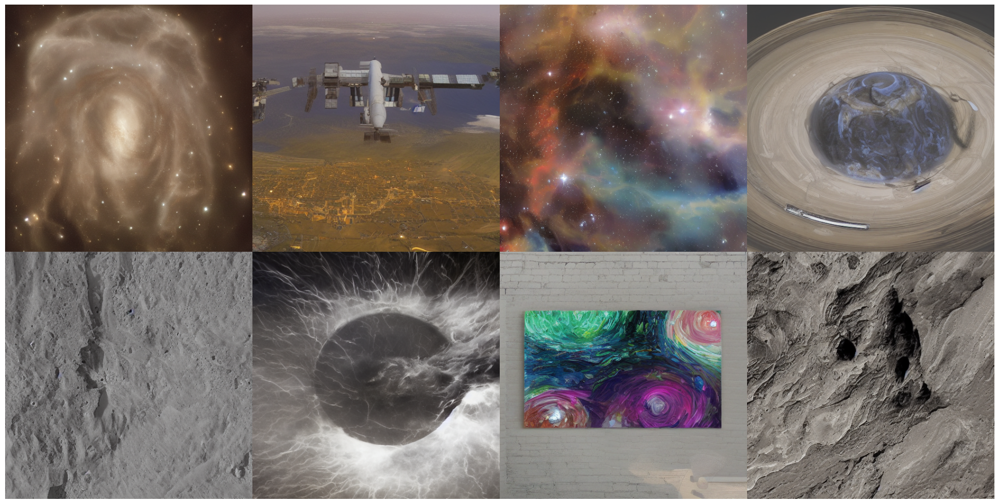


Image 1: A beautiful spiral galaxy with bright stars and cosmic dust

Image 2: The International Space Station orbiting Earth with city lights below

Image 3: A colorful nebula with glowing gas clouds and distant stars

Image 4: Saturn with its rings visible against the dark space background

Image 5: The Moon's surface with craters and shadows in high detail

Image 6: A solar eclipse showing the corona around the darkened Sun

Image 7: The Milky Way galaxy stretching across a starry night sky

Image 8: Mars surface with red rocks and a hazy orange atmosphere


In [ ]:
# Test generation with space-themed prompts
test_prompts = [
    "A beautiful spiral galaxy with bright stars and cosmic dust",
    "The International Space Station orbiting Earth with city lights below",
    "A colorful nebula with glowing gas clouds and distant stars",
    "Saturn with its rings visible against the dark space background",
    "The Moon's surface with craters and shadows in high detail",
    "A solar eclipse showing the corona around the darkened Sun",
    "The Milky Way galaxy stretching across a starry night sky",
    "Mars surface with red rocks and a hazy orange atmosphere"
]

print("Generating images with prompts:")
for i, prompt in enumerate(test_prompts):
    print(f"{i+1}. {prompt}")

# Generate images
generated_images = generate_images(test_prompts, num_inference_steps=50)

# Display as grid
image_grid = make_image_grid(generated_images, rows=2, cols=4)
plt.figure(figsize=(20, 10))
plt.imshow(image_grid)
plt.axis('off')
plt.tight_layout()
plt.show()

# Print prompts
for i, (prompt, img) in enumerate(zip(test_prompts, generated_images)):
    print(f"\nImage {i+1}: {prompt}")

Generating custom prompts:


Generating images: 100%|██████████| 4/4 [00:54<00:00, 13.73s/it]


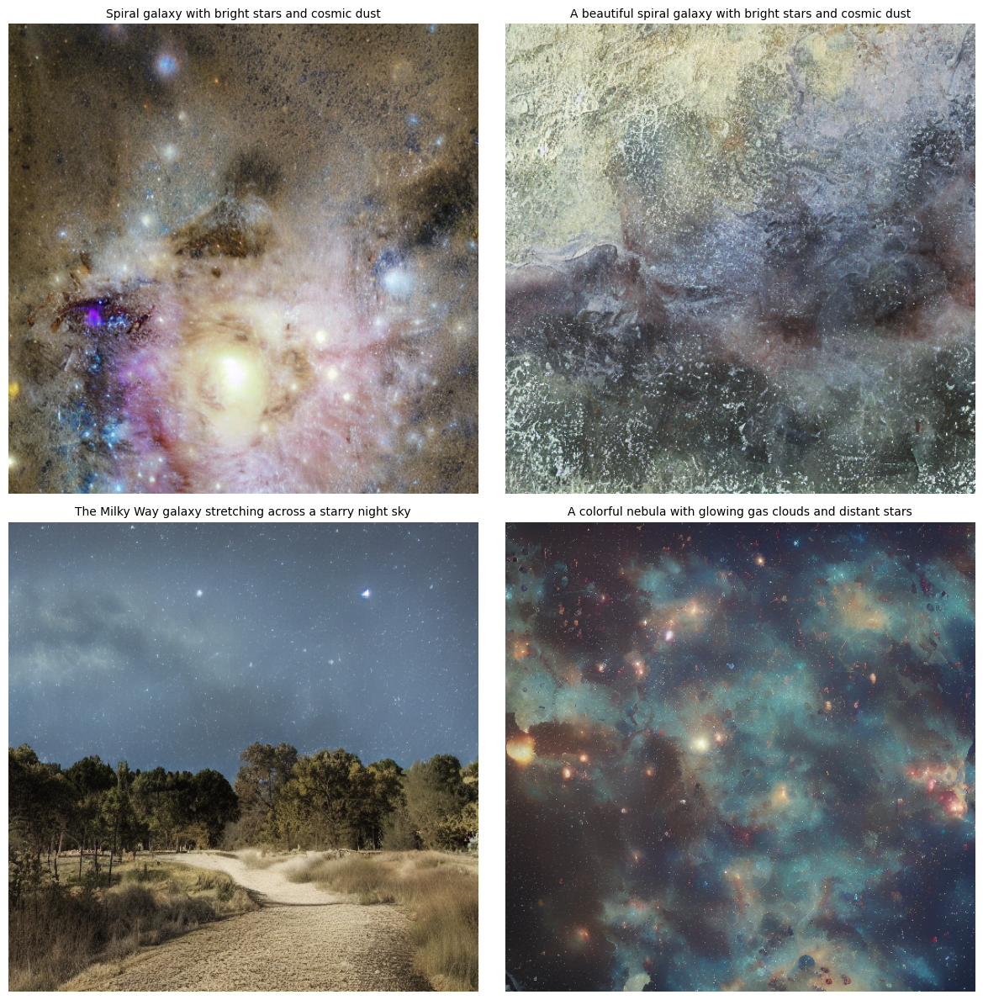

In [ ]:
import random

custom_prompts = [
    "Spiral galaxy with bright stars and cosmic dust",
    "A beautiful spiral galaxy with bright stars and cosmic dust",
    "The Milky Way galaxy stretching across a starry night sky",
    "A colorful nebula with glowing gas clouds and distant stars"
]

print("Generating custom prompts:")
# Use more inference steps for better quality
custom_images = generate_images(custom_prompts, num_inference_steps=80, seed=random.randint(100, 10000))

# Display in 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.flatten()

for i, (prompt, img) in enumerate(zip(custom_prompts, custom_images)):
    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(prompt, fontsize=10, wrap=True)

plt.tight_layout()
plt.show()

Generating custom prompts:


Generating images: 100%|██████████| 4/4 [00:55<00:00, 13.81s/it]


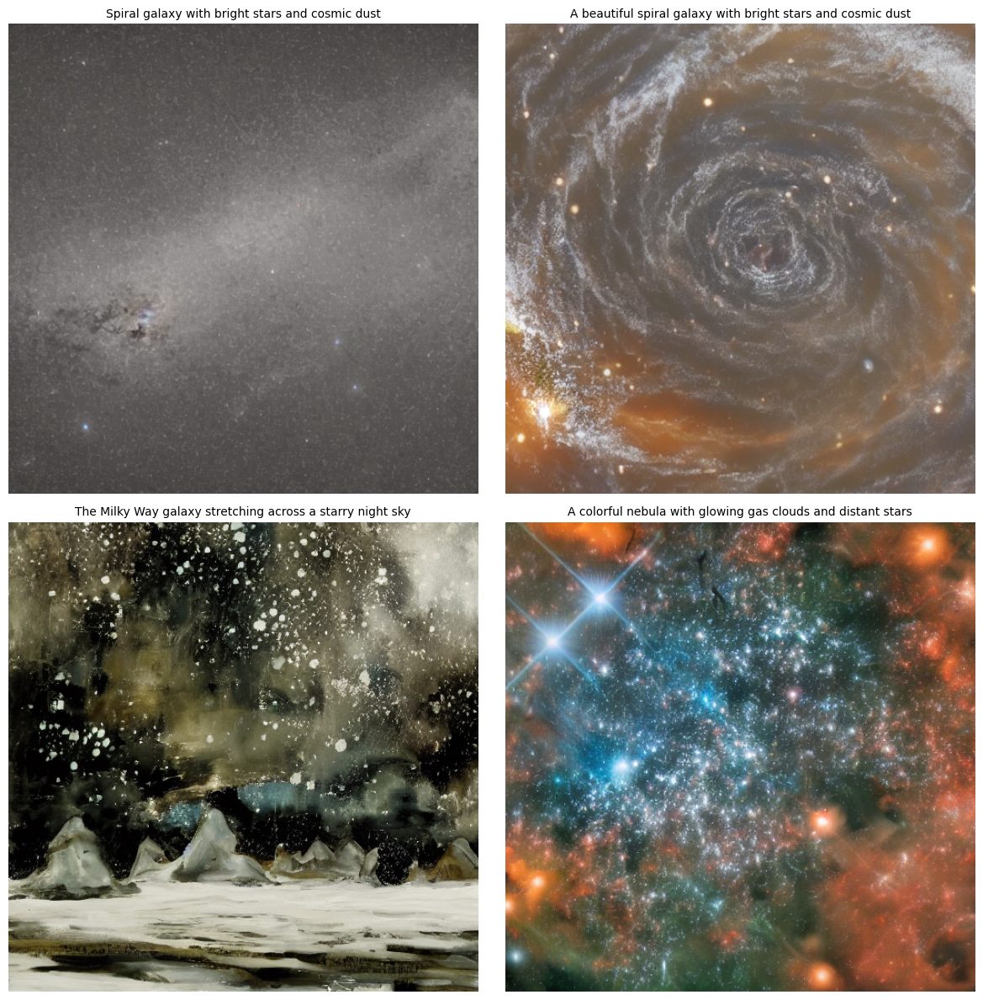

In [ ]:
import random

custom_prompts = [
    "Spiral galaxy with bright stars and cosmic dust",
    "A beautiful spiral galaxy with bright stars and cosmic dust",
    "The Milky Way galaxy stretching across a starry night sky",
    "A colorful nebula with glowing gas clouds and distant stars"
]

print("Generating custom prompts:")
custom_images = generate_images(custom_prompts, num_inference_steps=80, seed=random.randint(100, 10000))

# Display results
fig, axes = plt.subplots(2, 2, figsize=(12, 12))
axes = axes.flatten()

for i, (prompt, img) in enumerate(zip(custom_prompts, custom_images)):
    axes[i].imshow(img)
    axes[i].axis('off')
    axes[i].set_title(prompt, fontsize=10, wrap=True)

plt.tight_layout()
plt.show()